# Notebook 01: Stochastic Processes

**Goal:** Build the mathematical foundation — finite state spaces, transition matrices, probability evolution.

By the end of this notebook you will be able to:
- Define a stochastic process over a finite state space
- Evolve a probability distribution through a sequence of transition matrices
- Recognize that classical Markov chains are the simplest case


<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> This is a working copy of `01_stochastic_processes.ipynb`, expanded with longer
> explanations as I read through the framework. The original notebook's explanatory
> text appears here too, worded the same way in both.
>
> Added sections are marked **📖 In depth** and **🔭 Looking ahead**, plus study aids:
> 🧭 (before you start, how to use a cell), 📘 (glossary), 📚 (from the papers),
> 🧮 (worked derivations) and 📝 (recaps).
>
> No cell has been re-executed since the original run, so every stored output is
> exactly what that run produced. Earlier copies of this notebook are in
> `notebooks/_pre-2026-09-08/`.
---

<!-- expansion:01:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** It builds the vocabulary that every later notebook in the lab assumes: a finite list of configurations, a probability vector over them, a transition matrix that moves the vector forward in time, and the special case (the Markov chain) in which those matrices can be chained together step by step. Nothing quantum happens here except two short peeks ahead. The point is to make the classical baseline precise enough that, when notebook 03 shows a quantum system breaking it, you can say exactly *which* rule broke.

**What you need to know already.**
- Basic probability: what a conditional probability $P(A \mid B)$ is, and the law of total probability $P(A) = \sum_B P(A \mid B)\,P(B)$.
- Matrix-vector multiplication, and what it means for a matrix to have an inverse.
- Enough calculus to read $\frac{d}{dt}$ and $e^{x}$. The matrix exponential is explained when it appears.
- No quantum mechanics is required for this notebook.

**How long it takes.** Roughly 45–90 minutes to read carefully, longer if you do the "try this" experiments. The code itself runs in a few seconds.

**How to run it.**
- *Kernel → Restart & Run All* runs everything top to bottom. Or step through with **Shift+Enter**, one cell at a time, which is the better way to read it.
- Cells must run in order: later cells reuse variables (`T`, `L`, `p0`) defined earlier, and some cells redefine them (for example `p0` and `p` are reused with different values).
- The first code cell adds the folder one level up to Python's path, so `from isp.stochastic import ...` loads the lab's own package from `isp-lab/isp/`.
- The stored outputs you see were produced by the original run. Cells that use `np.random` (one cell in Section 2) will print different random draws if you re-run them, but the conclusions they print will not change.


<!-- expansion:01:glossary -->
### 📘 Glossary

Terms used in this notebook, in roughly the order they appear. Plain-English first, symbol second.

- **Configuration (state).** One of the distinct, mutually exclusive situations the system can be in, labelled $1, \dots, N$ (or $0, 1$ in the code). A coin's configurations are *heads* and *tails*. Barandes prefers "configuration" because in physics a "state" is often taken to include rates of change or momenta as well as configurations, and for an indivisible stochastic process those may not be well defined (Paper 2, §3.1, p. 8).
- **Configuration space $\mathcal{C}$.** The set of all configurations. Here it is always finite and small (two elements).
- **Probability distribution / probability vector $\mathbf{p}$.** A column of $N$ numbers, each $\ge 0$, adding to 1. Entry $p_i$ is the probability that the system is in configuration $i$. Barandes calls these *standalone* probabilities to separate them from conditional ones.
- **Transition matrix $T$ or $\Gamma(t \leftarrow t')$.** The square matrix collecting those conditional probabilities: entry $(i, j)$ is $p(i, t \mid j, t')$. Read the arrow right to left: "to time $t$, from time $t'$". The notebook writes $T$; the papers write $\Gamma$; they are the same object.
- **Stochastic matrix (column-stochastic).** A matrix with every entry $\ge 0$ and every column summing to 1. Every transition matrix must be one. Textbooks such as Norris use *row*-stochastic matrices instead (the transpose).
- **Composition / divisibility condition.** $\Gamma(t \leftarrow t_0) = \Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0)$ with the bridging factor $\Gamma(t \leftarrow t')$ a genuine stochastic matrix. A process satisfying this for every intermediate $t'$ is **divisible**; one that fails it is **indivisible**. This notebook calls the equation the *composition* (or *product*) *rule*.
- **Chapman–Kolmogorov equations.** In Barandes 2025 (arXiv:2507.21192, eq. 5), the marginalization consistency conditions that a textbook process's joint probabilities must satisfy. For a Markov process the composition rule follows from them; many other texts (for example Rivas, Huelga and Plenio's review of quantum non-Markovianity, eq. 4) give the name to the composition rule itself.
- **Markov property (memorylessness).** Conditioning on the whole past gives the same prediction as conditioning on the latest known configuration alone.
- **Markov chain.** A process with the Markov property. *Discrete-time* if it moves in steps of a fixed size; *continuous-time* (CTMC) if time is a real number.
- **Time-homogeneous.** The same rules apply at every moment, so a transition matrix depends only on elapsed time $t_2 - t_1$.
- **Generator (rate matrix) $L$.** For a continuous-time chain, the matrix of transition *rates*: off-diagonals $\ge 0$, columns summing to 0. When the rates do not change over time, $T(\Delta t) = e^{L\Delta t}$. Norris calls the row-convention version a **Q-matrix**.
- **Matrix exponential $e^{M}$ (`scipy.linalg.expm`).** The power series $I + M + M^2/2! + \cdots$. Not the same as exponentiating each entry.
- **Master equation.** $\frac{d\mathbf{p}}{dt} = L\mathbf{p}$: the rate of change of the distribution is a fixed linear function of the distribution.
- **Stationary distribution $\mathbf{p}^*$.** A distribution that the dynamics leaves unchanged: $T\mathbf{p}^* = \mathbf{p}^*$, or $L\mathbf{p}^* = 0$.
- **Division event.** In Barandes 2025 (arXiv:2507.21192, §2.2), an allowed *conditioning time*: a time from which the process's transition probabilities are defined. The set is assumed, without loss of generality, to include an initial time 0.


In [1]:
#import a bunch of python libraries
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import StochasticProcess, make_markov_chain
from isp.visualization import plot_probability_evolution, plot_transition_matrix


## 1. Probability Distributions as Column Vectors

A state space has $n$ states. A probability distribution is a column vector
$\mathbf{p}$ with non-negative entries summing to 1.


<!-- expansion:01:papers-configurations -->
### 📚 From the papers: configurations, and two kinds of ingredient

Barandes sets up every model from the same two pieces, and this section is the first of them.

- **The kinematics is a configuration space.** In "The Stochastic-Quantum Correspondence" (arXiv:2302.10778, §2.1) an indivisible stochastic process is "a model consisting of two basic ingredients: a configuration space $\mathcal{C}$; and a dynamical law in the form of a family of transition maps $\Gamma_{t\leftarrow t_0}$". For a finite system, $\mathcal{C} \equiv \{1, \dots, N\}$.
- **Probabilities are contingent; laws are fixed.** The same paragraph says the configuration space and transition maps "will constitute the fixed features of the model, whereas the probability distributions will be contingent features allowed to vary from one physical instantiation or run of the model to another." The 2025 paper ("Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192, §2.1) repeats the split, calling $\mathcal{C}$ the model's "kinematics" and the standalone distribution its "informational or 'epistemic' content."
- **The conditions on a distribution** are the ordinary ones: $0 \le p(i,t) \le 1$ and $\sum_i p(i,t) = 1$ (2507.21192, eq. 1; 2302.10778, eqs. 2–3).

**Why this matters for the code.** The vector `p` in the next cell is the contingent part. You may set it to anything that is non-negative and sums to 1, and the transition matrices of Section 2 are not supposed to change when you do. Keep that separation in mind: later notebooks ask whether a *law* (a matrix) can be split in time, and the answer must not depend on which starting vector you happened to pick.

**About the ket labels.** The code prints `|0⟩` and `|1⟩`. That is borrowed quantum notation, used here only as labels for the two configurations. Nothing in this notebook is a quantum state vector; `p` holds probabilities, not amplitudes.


In [2]:
# Two-state system: coin with bias 70/30
p = np.array([0.7, 
              0.3])
print(f"State |0⟩ probability: {p[0]}")
print(f"State |1⟩ probability: {p[1]}")
print(f"Normalization check (should be 1.0): {p.sum()}")
print(p[:, np.newaxis])

State |0⟩ probability: 0.7
State |1⟩ probability: 0.3
Normalization check (should be 1.0): 1.0
[[0.7]
 [0.3]]


<!-- expansion:01:howto-coin -->
### 🧭 How to use this cell / what to look at

- **What it computes:** nothing beyond storing a two-entry distribution and checking it.
- **What to look at:** the three printed numbers `0.7`, `0.3` and the normalization check `1.0`. The last line prints the same vector reshaped with `p[:, np.newaxis]` into a $2 \times 1$ column, which is the shape the linear algebra assumes.
- **Why the column shape matters:** a column vector is what lets a transition matrix act from the left, $T\mathbf{p}$. NumPy's `@` operator treats a 1-D array as a column when it sits to the right of a matrix, so later cells can keep `p` one-dimensional.

**Try this.**
1. Change `p` to `np.array([0.7, 0.4])`. The check prints `1.1`. Nothing stops you, because this cell does not *enforce* normalization; it only reports it. Predict what `T @ p` would give in Section 2 (its entries will sum to 1.1, because a column-stochastic matrix preserves the total, whatever the total is).
2. Try `np.array([1.2, -0.2])`. It sums to 1 but is not a probability distribution. Normalization alone is not enough; non-negativity is the second, separate condition. This same pair of conditions comes back for matrices in Section 2, and the "Looking ahead" cell near the end shows that quantum mechanics breaks the second, not the first.


<!-- expansion:01:recap-s1 -->
### 📝 Recap: Section 1

- A system has a finite set of **configurations**; a **probability distribution** over them is a column vector with non-negative entries that sum to 1.
- Two separate conditions define a valid distribution: **non-negativity** and **normalization**. Passing one does not imply the other.
- In Barandes' language the configuration space is a *fixed* feature of a model, and the distribution is *contingent*: it can differ from run to run.


## 2. Transition Matrices

A transition matrix $T$ maps one distribution to the next:
$$\mathbf{p}(t_2) = T \cdot \mathbf{p}(t_1)$$

Each **column** of $T$ must sum to 1 — it's a probability distribution
over next states given a current state.


<!-- expansion:01:papers-gamma -->
### 📚 From the papers: the transition matrix $\Gamma(t \leftarrow t_0)$

The matrix $T$ in this section is what Barandes writes as $\Gamma(t \leftarrow t_0)$. His definition, in 2302.10778 §2.1, is a direct transcription of the plain-English one above:

- **Entries are conditional probabilities.** $\Gamma_{ij}(t \leftarrow t_0) \equiv p(i, t \mid j, t_0)$ (eq. 1): "the conditional probability for the system to be in its $i$th configuration at the target time $t$, given that the system is in its $j$th configuration at the conditioning time $t_0$." Row index = target configuration, column index = conditioning configuration, exactly as the In-depth cell below argues.
- **Non-negativity and normalization** of those entries (eqs. 2–3), with the normalization sum taken over $i$, that is, down a column.
- **Evolution is the law of total probability.** $p_i(t) = \sum_j \Gamma_{ij}(t \leftarrow t_0)\,p_j(t_0)$ (eq. 4), or in matrix form $\mathbf{p}(t) = \Gamma(t \leftarrow t_0)\,\mathbf{p}(t_0)$ (eq. 5). The paper then says these conditions "identify it as a (column) stochastic matrix for each pair of times."
- **Continuity.** As $t \to t_0$, $\Gamma(t \leftarrow t_0)$ is assumed to approach the identity matrix.

Two things in that definition are easy to miss and matter later.

1. **Matrix-vector multiplication is not an extra assumption.** It *is* the law of total probability written compactly. So any stochastic process at all, Markov or not, evolves its distribution from a conditioning time by a matrix product. What is *not* automatic is chaining two such products (that is the divisibility question).
2. **$\Gamma$ is indexed by a pair of times.** There is one matrix for each (target, conditioning) pair, not one matrix per "step." The In-depth cell on what the code means by "a process" (just below the three-step example) turns this into a design point about the lab's code.


### 📖 In depth: why *columns* sum to 1, and not rows

Everything below follows from what a single entry $T_{ij}$ means. Write out $\mathbf{p}' = T\mathbf{p}$ component by component:

$$p'_i = \sum_j T_{ij}\, p_j$$

which forces the reading

$$T_{ij} = P(\text{next state is } i \mid \text{current state is } j)$$

**Row index = destination. Column index = source.** That one choice generates every other rule on this page.

#### The argument

Fix a column $j$. That column is the complete list of answers to *"given that I am in state $j$ right now, where do I go next?"* Those destinations are mutually exclusive and exhaustive — **you have to go somewhere**, even if "somewhere" means staying put. So the total probability over all destinations is 1:

$$\sum_i T_{ij} = 1 \qquad \text{for every column } j$$

A column is a genuine probability distribution: it is conditioned on *one fixed* starting state, so it must normalize.

#### Why rows are not constrained

Row $i$ reads $\big[\,P(\to i \mid \text{from } 0),\; P(\to i \mid \text{from } 1),\; \dots\big]$ — probabilities conditioned on **different premises**. Adding them is a category error, like adding *"chance of rain given it's July"* to *"chance of rain given it's January."* Nothing constrains that sum; it can land above or below 1. The next cell shows this on the notebook's own matrix.

#### What the condition actually buys: conservation of probability

The column-sum rule is exactly the condition guaranteeing that $T$ maps valid distributions to valid distributions:

$$\sum_i p'_i \;=\; \sum_i \sum_j T_{ij} p_j \;=\; \sum_j \Big(\underbrace{\sum_i T_{ij}}_{=\,1}\Big) p_j \;=\; \sum_j p_j \;=\; 1$$

Swap the order of summation, and the inner sum *is* the column sum. So:

> **Columns sum to 1 $\iff$ total probability is conserved forever.**

That is the entire content of the axiom. Non-negativity handles *"entries are probabilities"*; column sums handle *"they are a complete set of probabilities."*

A compact restatement worth memorizing — with $\mathbf{1}$ the all-ones column vector:

$$\mathbf{1}^{T} T = \mathbf{1}^{T}$$

i.e. **$\mathbf{1}^T$ is a left eigenvector of every transition matrix, with eigenvalue exactly 1.** Section 3 below differentiates this to get the generator condition.

#### ⚠️ Convention trap

**Most probability textbooks use the opposite convention** — including `norris.pdf` in `papers to study/`. They use **row**-stochastic matrices: row vectors, $\mathbf{p}' = \mathbf{p}T$, multiplication from the right, and **rows** summing to 1. The two conventions are related by transpose. Neither is more correct, but reading Norris in the morning and these notebooks in the afternoon without noticing the switch will cost an hour.

**Why this framework uses columns:** quantum mechanics is already written that way. States are column kets and operators act from the left:

$$\text{quantum:}\quad |\psi(t)\rangle = U(t)\,|\psi(0)\rangle \qquad\qquad \text{stochastic:}\quad \mathbf{p}(t) = T(t)\,\mathbf{p}(0)$$

Choosing column-stochastic makes these two lines structurally identical. That is not cosmetic tidiness — the stochastic-quantum correspondence builds each transition matrix entry by entry from a unitary-type matrix, $\Gamma_{ij}(t \leftarrow 0) = |\Theta_{ij}(t \leftarrow 0)|^2$ (2302.10778, eq. 12), so the two matrices need the same index reading: row = target, column = source. Notebook 04 cashes this in.

*Reference: §2 of arXiv 2302.10778 (The Stochastic-Quantum Correspondence).*

In [3]:
# Column-stochastic: T[i,j] = P(go to state i | currently in state j)
T = np.array([[0.8, 0.3],
              [0.2, 0.7]])

print("Column sums (must be 1.0):", T.sum(axis=0))

# Evolve p one step
p_next = T @ p
print(f"\np(t=0) = {p}")
print(f"p(t=1) = {p_next}")


Column sums (must be 1.0): [1. 1.]

p(t=0) = [0.7 0.3]
p(t=1) = [0.65 0.35]


<!-- expansion:01:howto-first-step -->
### 🧭 How to use this cell / what to look at

- **What it computes:** the column sums of `T` (both `1.`), then one step of evolution `p_next = T @ p` from the 70/30 coin of Section 1.
- **The number that matters:** `p(t=1) = [0.65 0.35]`. Check it by hand, one row at a time, each row being "all the ways to end up in that configuration":

$$p_0(1) = \underbrace{0.8 \times 0.7}_{\text{stay at 0}} + \underbrace{0.3 \times 0.3}_{\text{1}\to\text{0}} = 0.56 + 0.09 = 0.65,
\qquad
p_1(1) = 0.2 \times 0.7 + 0.7 \times 0.3 = 0.14 + 0.21 = 0.35$$

Each term is (probability of starting in $j$) × (probability of going from $j$ to $i$), summed over $j$: the law of total probability, term by term.

- **Also notice:** `0.65 + 0.35 = 1`. Total probability was conserved, as the column-sum rule guarantees.

**Try this.**
1. Swap the two off-diagonal entries so `T = [[0.8, 0.2], [0.3, 0.7]]`. The column sums become `[1.1, 0.9]`, so `T` is no longer column-stochastic, and `p_next` will no longer sum to 1. (It is still *row*-stochastic: this is the textbook convention applied in the wrong slot.)
2. Set `p = np.array([0.6, 0.4])` and re-run. Predict before you look: `p_next` equals `p` exactly. The worked derivation after the next code cell explains why.


In [4]:
# 📖 In depth: columns are constrained, rows are not.
# Same T as the cell above.

print("T =")
print(T, "\n")

print(f"  column sums : {T.sum(axis=0)}   <- must be 1, always")
print(f"  row sums    : {T.sum(axis=1)}   <- no constraint; here one is >1\n")

# Read the entries out loud to fix the index convention:
for j in range(2):
    for i in range(2):
        print(f"  T[{i},{j}] = {T[i,j]:.1f}  =  P(go to state {i} | currently in state {j})")
    print(f"  {'':>10}------  column {j} total = {T[:, j].sum():.1f}  (you must go somewhere)\n")

# Conservation of probability is a *consequence*, not a separate assumption:
for trial in range(3):
    p_test = np.random.dirichlet([1, 1])       # a random valid distribution
    print(f"  sum(p) = {p_test.sum():.6f}  ->  sum(T @ p) = {(T @ p_test).sum():.6f}")

# ...and it holds for the compact form too:  1^T T = 1^T
ones = np.ones(2)
print(f"\n  1^T @ T = {ones @ T}   (left eigenvector of T, eigenvalue 1)")

T =
[[0.8 0.3]
 [0.2 0.7]] 

  column sums : [1. 1.]   <- must be 1, always
  row sums    : [1.1 0.9]   <- no constraint; here one is >1

  T[0,0] = 0.8  =  P(go to state 0 | currently in state 0)
  T[1,0] = 0.2  =  P(go to state 1 | currently in state 0)
            ------  column 0 total = 1.0  (you must go somewhere)

  T[0,1] = 0.3  =  P(go to state 0 | currently in state 1)
  T[1,1] = 0.7  =  P(go to state 1 | currently in state 1)
            ------  column 1 total = 1.0  (you must go somewhere)

  sum(p) = 1.000000  ->  sum(T @ p) = 1.000000
  sum(p) = 1.000000  ->  sum(T @ p) = 1.000000
  sum(p) = 1.000000  ->  sum(T @ p) = 1.000000

  1^T @ T = [1. 1.]   (left eigenvector of T, eigenvalue 1)


<!-- expansion:01:derivation-two-state -->
### 🧮 Worked derivation: where any two-state chain ends up

Norris works the general two-state chain in closed form (*Markov Chains*, Example 1.1.4, row convention). Here is the same calculation in this notebook's column convention, applied to the notebook's own `T`. It explains the `0.65` above and predicts where repeated steps go.

**Step 1 — parametrize.** Any $2\times 2$ column-stochastic matrix is fixed by two numbers: the chance of leaving 0, call it $a$, and the chance of leaving 1, call it $b$:

$$T = \begin{pmatrix} 1-a & b \\ a & 1-b \end{pmatrix}, \qquad \text{here } a = 0.2,\; b = 0.3.$$

**Step 2 — find the fixed point.** A stationary distribution satisfies $T\mathbf{p}^* = \mathbf{p}^*$. The top row gives $(1-a)p_0^* + b\,p_1^* = p_0^*$, i.e. $a\,p_0^* = b\,p_1^*$: *flow out of 0 equals flow into 0.* With $p_0^* + p_1^* = 1$:

$$\mathbf{p}^* = \frac{1}{a+b}\begin{pmatrix} b \\ a \end{pmatrix} = \frac{1}{0.5}\begin{pmatrix} 0.3 \\ 0.2 \end{pmatrix} = \begin{pmatrix} 0.6 \\ 0.4 \end{pmatrix}.$$

**Step 3 — track the deviation.** Write $p_0 = 0.6 + d$, so $p_1 = 0.4 - d$. Apply $T$:

$$p_0' = (1-a)(0.6 + d) + b(0.4 - d) = \underbrace{(1-a)(0.6) + b(0.4)}_{=\,0.6} + (1 - a - b)\,d.$$

So the deviation is multiplied by $1 - a - b = 0.5$ at every step. That number is $T$'s second eigenvalue (the first is 1, belonging to $\mathbf{p}^*$).

**Step 4 — check against the stored output.** The coin started at $p_0 = 0.7$, deviation $d = 0.1$. One step halves it to $0.05$, giving $p_0 = 0.65$: exactly the printed `p(t=1)`. Continuing: $0.625,\ 0.6125,\ 0.60625, \dots \to 0.6$.

**Step 5 — the general formula.** After $n$ steps, $p_0(n) = \frac{b}{a+b} + (1-a-b)^n\big(p_0(0) - \frac{b}{a+b}\big)$. With $p_0(0) = 1$ this is Norris's $p_{11}^{(n)} = \frac{\beta}{\alpha+\beta} + \frac{\alpha}{\alpha+\beta}(1-\alpha-\beta)^n$.

**What to take away.** A time-homogeneous chain has a *single* matrix, so its long-run behaviour is controlled by that matrix's eigenvalues. Section 3's generator does the same thing in continuous time, with $e^{-(a+b)t}$ in place of $(1-a-b)^n$.


In [5]:
# Build a StochasticProcess and evolve over multiple steps
T1 = np.array([[0.8, 0.3], [0.2, 0.7]])
T2 = np.array([[0.9, 0.1], [0.1, 0.9]])
T3 = np.array([[0.6, 0.5], [0.4, 0.5]])

proc = StochasticProcess(
    states=["heads", "tails"],
    transitions=[T1, T2, T3],
    times=[0.0, 1.0, 2.0, 3.0]
)

p0 = np.array([1.0, 0.0])  # start certain in "heads"
distributions = proc.evolve(p0)

for t, p in zip(proc.times, distributions):
    print(f"t={t:.1f}: P(heads)={p[0]:.3f}  P(tails)={p[1]:.3f}")


t=0.0: P(heads)=1.000  P(tails)=0.000
t=1.0: P(heads)=0.800  P(tails)=0.200
t=2.0: P(heads)=0.740  P(tails)=0.260
t=3.0: P(heads)=0.574  P(tails)=0.426


<!-- expansion:01:howto-three-steps -->
### 🧭 How to use this cell / what to look at

- **What it computes:** a three-step process with a *different* matrix at each step (`T1`, `T2`, `T3`), started certain in heads, `p0 = [1, 0]`. `proc.evolve(p0)` applies the increments one after another and returns the distribution at each of the four times.
- **The numbers that matter:** `P(heads)` goes `1.000 → 0.800 → 0.740 → 0.574`. Each is one matrix-vector product on the previous line:

$$0.8 = 0.8 \times 1 + 0.3 \times 0, \qquad 0.74 = 0.9 \times 0.8 + 0.1 \times 0.2, \qquad 0.574 = 0.6 \times 0.74 + 0.5 \times 0.26.$$

- **Why this process is not time-homogeneous:** the rule changes between steps. It is still divisible at its stored times *by construction*, because it is literally stored as a product of stochastic increments (see the In-depth cell below on what that representation assumes).

### 🧮 Worked derivation: the whole process as one matrix

Because each step is a matrix product, the matrix from $t=0$ to $t=3$ is the product of the increments, latest on the left:

$$T(3 \leftarrow 0) = T_3\,T_2\,T_1 = \begin{pmatrix} 0.574 & 0.534 \\ 0.426 & 0.466 \end{pmatrix}.$$

Its first column is the final distribution printed above, because `p0` picks out column 0. This is what `proc.transition_from_to(0, 3)` returns. The order matters: $T_1$ acts first, so it sits on the right.

**Try this.**
1. Reverse the order: `transitions=[T3, T2, T1]`. Predict first: matrices generally do not commute, so the answer changes. The final `P(heads)` becomes `0.590` instead of `0.574`.
2. Start in tails, `p0 = np.array([0.0, 1.0])`. The final line should be the *second* column of $T(3 \leftarrow 0)$ above.
3. Replace `T2` with `np.array([[0.5, 0.5], [0.5, 0.5]])`. After that step the distribution is `[0.5, 0.5]` whatever came before: this matrix erases all information about the past. Its determinant is 0, so it has no inverse. Keep this in mind for notebooks 02 and 05, where a singular matrix blocks the inverse-based divisibility test.


### 📖 In depth: what the code means by "a process" — increments, and the family they came from

There is a modelling decision buried in `isp/stochastic.py` that looks like bookkeeping and is not. It decides what can even be *expressed* later, so it is worth surfacing now, in the notebook where the class first appears.

#### Two ways to write down the same thing

`StochasticProcess` stores a list of **increments** — one matrix per gap between consecutive times — and derives everything else by chaining them:

```python
transitions: List[np.ndarray]   # transitions[i]: T from times[i] to times[i+1]

def transition_from_to(self, i, j):
    T = np.eye(n)
    for k in range(i, j):
        T = self.transitions[k] @ T     # compose the increments
    return T
```

Barandes does not define a process that way. In the papers an indivisible process **is** its family of transition matrices, one for each conditioning time $t_i$ the model allows (a *division event*; an initial time is always taken to be one of them) and each target time $t_j$,

$$\big\{\,\Gamma(t_j, t_i)\,\big\}$$

with no claim that any member factors into smaller pieces. The two descriptions carry different assumptions:

| | `StochasticProcess` (increments) | the family $\{\Gamma(t_j,t_i)\}$ |
|---|---|---|
| stores | one matrix per adjacent gap | one matrix per (conditioning, target) pair it supplies |
| derives | $T(t_i \to t_k)$ as a product | nothing — the pairs are given |
| assumes | an increment exists, and composing is legitimate | nothing |
| divisibility is | **built into the storage** | **a question you can ask** |

That last row is the whole point. If a process is written as a chain of increments, you have already assumed it can be cut at every stored time and reassembled — which is divisibility, asserted rather than tested. **The representation smuggles in the conclusion.**

#### Where this bites, twice

**First, in notebook 03.** The qubit process is *defined* by its absolute matrices $T(t_0 \to t)$, and `isp/quantum.py` back-solves for increments:

```python
T_incr = T_next @ np.linalg.inv(T_prev) if i > 0 else T_next
```

So the objects sitting in `transitions` are whatever matrix is *forced* by that division — and for a quantum process they need not be transition matrices at all. Run it and the fourth increment is

$$\begin{pmatrix} -2.4415 & 3.4415 \\ 3.4415 & -2.4415 \end{pmatrix}$$

Columns still sum to 1. Entries are wildly negative. It is a legal NumPy array and a meaningless transition matrix — and that is precisely the diagnostic notebook 03 is built around. Note what this means about the class: `StochasticProcess` will happily hold matrices that are not stochastic. Nothing validates them on the way in.

**Second, in notebook 05, where it stops working at all.** For the balanced double slit, $\Gamma(t_1,t_0)$ is *singular*. A singular matrix has no inverse, so the increment cannot be back-solved even formally. Worse, for this model no matrix at all — non-negative or signed — satisfies $X\,\Gamma(t_1,t_0) = \Gamma(t_2,t_0)$: some pairs of starting distributions that $\Gamma(t_1,t_0)$ sends to the same distribution at $t_1$ are sent to different distributions at $t_2$, and nothing applied at $t_1$ can restore a difference that is already gone. The process cannot be written as increments without changing the physics.

Hence the second class in the same module:

```python
@dataclass
class PairwiseProcess:
    matrices: Dict[Tuple[int, int], np.ndarray]   # (i, j) -> Gamma(t_j, t_i)
```

It stores the family directly, and its `__post_init__` enforces on every member exactly the two conditions from Section 2 — non-negative entries, columns summing to 1 — and nothing else. No composition is assumed, so divisibility stays a question.

> **Read the two classes as a claim about physics, not about code.** `StochasticProcess` is the right container for a process that *is* built out of steps. `PairwiseProcess` is the right container for one that might not be. Barandes' whole thesis is that quantum systems are the second kind, so the lab needs the second container to state the thesis at all.

<!-- expansion:01:papers-markov-composition -->
### 📚 From the papers: textbook processes, the Markov property, and where "indivisible" departs

Barandes' 2025 paper (arXiv:2507.21192) separates two cases. This is the cleanest statement of what the code above is or is not assuming.

**§2.1, Textbook stochastic processes.**
- A textbook process has a "Kolmogorov tower" of first-, second-, third-order and higher conditional probabilities $p(i,t \mid j_1,t_1)$, $p(i,t \mid j_1,t_1; j_2,t_2)$, … (eq. 3), plus marginalization consistency conditions the paper calls the Chapman–Kolmogorov equations (eq. 5).
- **Markovian** means every higher-order transition probability equals the first-order one for the latest conditioning time: the latest time "'screens off' all the earlier conditioning times."
- From that, the paper says "it follows immediately" that first-order transition probabilities compose (eq. 7). Organizing them as $\Gamma_{ij}(t \leftarrow t') \equiv p(i,t \mid j,t')$ (eq. 8) gives the product rule $\Gamma(t \leftarrow t_n) = \Gamma(t \leftarrow t_1)\cdots\Gamma(t_{n-1} \leftarrow t_n)$ (eq. 13) and the **divisibility condition** $\Gamma(t \leftarrow t_0) = \Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0)$ (eq. 14).
- A discrete-time Markov chain is the simplest case: $\Gamma(n\,\delta t \leftarrow 0) = \Gamma^n$ (eq. 15).
- **Memory** in a non-Markovian textbook process means conditioning on more past times changes the answer, $p(i,t \mid j_1,t_1) \ne p(i,t \mid j_1,t_1; j_2,t_2)$ (eq. 16).

**§2.2, Indivisible stochastic processes.**
- The laws "contain only first-order transition probabilities connecting target times $t$ with conditioning times $t_0$" (eq. 18). The only available consistency relation is the law of total probability, $\mathbf{p}(t) = \Gamma(t \leftarrow t_0)\,\mathbf{p}(t_0)$ (eqs. 19–20).
- No assumption is made that $\Gamma(t \leftarrow t')$ exists for every $t'$. The allowed conditioning times are called **division events**, and they include an initial time 0.

**How this maps onto the two classes.** `StochasticProcess` stores increments and multiplies them: that is eq. 13, the textbook-Markov structure. `PairwiseProcess` stores one $\Gamma$ for each pair of times it is given and asserts nothing about products: closer to §2.2.

**Two names to keep apart.** The product rule $T(t_2,t_0) = T(t_2,t_1)\,T(t_1,t_0)$ is the *composition rule*, or in Barandes' terms the *divisibility condition* (eq. 14). The *Chapman-Kolmogorov equations* in his paper are something more basic: the marginalization conditions on joint probabilities (eq. 5), which every textbook process satisfies, Markov or not. The product rule follows from them only once the Markov property is added. Many other texts, for example Rivas, Huelga and Plenio's review of quantum non-Markovianity (arXiv:1405.0303, eq. 4), call the product rule itself "the Chapman-Kolmogorov equation," so check which usage a source intends.


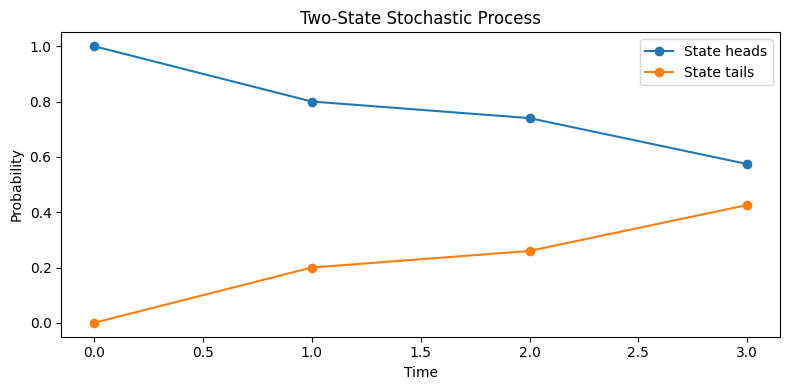

In [6]:
fig = plot_probability_evolution(proc, p0, title="Two-State Stochastic Process")
plt.tight_layout()
plt.show()


<!-- expansion:01:howto-plot1 -->
### 🧭 How to use this cell / what to look at

- **What it draws:** the four distributions from the cell above, one line per configuration ("State heads" and "State tails") with a marker at each stored time. `plot_probability_evolution` simply calls `proc.evolve(p0)` again and plots the result.
- **What to look for:** the two lines are mirror images about 0.5, because at every time they must add to 1. The heads line passes through $1.0, 0.8, 0.74, 0.574$ at $t = 0, 1, 2, 3$, matching the printout.
- **What the straight segments mean:** nothing physical. The process is only defined at the four stored times; the plotting library joins the dots. A stochastic process given as increments says nothing about what happens *between* stored times, which is exactly why the divisibility question ("is there a valid matrix for a sub-interval?") is a real question.


<!-- expansion:01:recap-s2 -->
### 📝 Recap: Section 2

- A **transition matrix** $T = \Gamma(t \leftarrow t')$ has entries $p(i, t \mid j, t')$: row = destination, column = source.
- It must be **column-stochastic**: entries $\ge 0$, each column sums to 1. The column condition is exactly what conserves total probability; rows are unconstrained.
- $\mathbf{p}(t) = T\,\mathbf{p}(t')$ is just the law of total probability. Chaining several steps multiplies their matrices, latest on the left.
- A single fixed matrix drives the distribution toward a **stationary distribution**, at a speed set by its other eigenvalue(s); for the notebook's `T` that is $(0.6, 0.4)$ and $0.5$ per step.
- `StochasticProcess` stores **increments**, which builds divisibility into the representation; `PairwiseProcess` stores the pairwise family $\{\Gamma\}$ and leaves divisibility as a question.


## 3. Continuous-Time Markov Chains

The simplest continuous-time stochastic processes are time-homogeneous
continuous-time Markov chains (CTMCs), generated by a fixed **generator matrix** $L$:
$$T(t_2, t_1) = e^{L \cdot (t_2 - t_1)}$$

Generator convention: off-diagonal entries ≥ 0 (transition rates),
columns of $L$ sum to 0.


<!-- expansion:01:papers-norris-q -->
### 📚 From the papers: Norris on Q-matrices and $e^{tQ}$

The standard textbook source for this section is Norris, *Markov Chains*, Chapter 2. The statements below are from §2.1 ("Q-matrices and their exponentials"). Norris uses the row convention, so every statement transposes to this notebook's: his $Q$ is $L^{\mathsf T}$, and his rows become our columns.

- **Definition of a Q-matrix** (Norris's generator): (i) $0 \le -q_{ii} < \infty$; (ii) $q_{ij} \ge 0$ for $i \ne j$; (iii) each row sums to 0. "The diagonal entry $q_{ii}$ is then $-q_i$, making the total row sum zero," where $q_i$ is "the rate of leaving $i$."
- **Theorem 2.1.1.** For a finite $I$ and $P(t) = e^{tQ}$: (i) $P(s+t) = P(s)P(t)$, the semigroup property; (ii) and (iii) $P(t)$ is the unique solution of the forward equation $\frac{d}{dt}P = PQ$ and of the backward equation $\frac{d}{dt}P = QP$, with $P(0) = I$; (iv) $\left(\frac{d}{dt}\right)^k P(t)\big|_{t=0} = Q^k$.
- **Theorem 2.1.2.** "A matrix $Q$ on a finite set $I$ is a Q-matrix if and only if $P(t) = e^{tQ}$ is a stochastic matrix for all $t \ge 0$." The proof starts from $P(t) = I + tQ + O(t^2)$, the same small-$t$ expansion the In-depth cells use.

**Why Theorem 2.1.2 is the key fact for this lab.** It says the two generator conditions in the cell above (off-diagonals $\ge 0$, columns sum to 0) are not just sufficient but *necessary* for $e^{L\Delta t}$ to be a transition matrix at every $\Delta t$. Combined with the semigroup property, every sub-interval of a CTMC has a valid transition matrix. That is the precise sense in which "continuous-time Markov chains are always divisible," stated later in this section.

*Not in Norris:* the column convention and the symbol $L$ are this lab's (and Barandes'), not Norris's.


### 📖 In depth: what *is* a Markov chain?

Before unpacking $T(\Delta t) = e^{L\Delta t}$, it's worth pinning down the thing being generated — because in this framework the definition is not throat-clearing. It is the property that quantum mechanics will turn out to **violate**.

#### The definition: memorylessness

A stochastic process is a **Markov chain** if

$$P\big(X_{t+1} = i \;\big|\; X_t = j,\; X_{t-1} = k,\; \dots,\; X_0 = m\big) \;=\; P\big(X_{t+1} = i \;\big|\; X_t = j\big)$$

In words: **the future depends on the present only — not on the path taken to reach it.** Conditioning on the entire history tells you nothing beyond conditioning on where you are right now. The present state is a *sufficient summary* of everything the past can contribute.

This is called the **Markov property**, or memorylessness.

| Markov | Not Markov |
|---|---|
| A board game where your next move depends only on the square you occupy | A card game where what's already been dealt changes the odds |
| Radioactive decay — an undecayed nucleus has no "age" | A machine whose failure rate rises with hours run |
| Brownian motion | A process with feedback, lag, or hysteresis |

The second column is *non-Markovian*: the past leaks into the future through some channel the current state doesn't capture.

#### Why this matters here

Notice what the Markov property buys. If the present screens off the past, then to get from $t_0$ to $t_2$ you can always stop at an intermediate $t_1$, ask "where am I now?", and restart cleanly — the process has no memory of how it arrived. That is precisely the composition (product) rule

$$T(t_2, t_0) \;=\; T(t_2, t_1)\, T(t_1, t_0)$$

which is the **divisibility condition**. Memorylessness is what makes it hold: the conditional probabilities from $t_1$ do not depend on where the process was at $t_0$, so they chain onto the ones from $t_0$. (Barandes reserves the name *Chapman–Kolmogorov equations* for the marginal-consistency conditions on a process's joint probabilities; the product rule follows from them only when the process is Markov. Many textbooks give the product rule itself that name.)

So the logical chain that the rest of this lab hangs on:

$$\textbf{Markov} \;\Longrightarrow\; \textbf{divisible}
\qquad\text{and therefore}\qquad
\textbf{indivisible} \;\Longrightarrow\; \textbf{non-Markovian}$$

Barandes' claim is that quantum systems live on the right-hand side: their transition matrices are generically indivisible. Be careful with the word "memory" here. Divisibility constrains only the first-order transition matrices $\Gamma(t \leftarrow t')$ (Paper 1, §2.2). Any textbook process with indivisible first-order matrices must be non-Markovian, but the indivisible process itself specifies no higher-order conditional probabilities; what it exhibits is first-order matrices that fail to compose. Barandes says as much: indivisible processes are not "non-Markovian only in the familiar sense of requiring the specification of higher-order conditional probabilities" (Paper 3, §1, p. 1).

> ⚠️ **The converse fails, and the distinction is the whole point.** Not every non-Markovian process is indivisible. Plenty of ordinary classical processes have memory and are still divisible — you can still factor them through intermediate times using valid stochastic matrices. **Indivisibility is a strictly stronger condition than "has memory."** It is also the *generic* case: Barandes notes that a transition matrix $\Gamma(t \leftarrow t_0)$ "will generically be indivisible" (2302.10778 §2.1, in the sentence introducing eq. 6, citing Milz & Modi 2021), and his stochastic-quantum correspondence covers a "highly general class" of processes, divisible or not (Paper 1, §1; Paper 2, abstract), with indivisible as the generic case. So the line this lab tracks is divisible versus indivisible, not simple versus complicated classical behavior. Notebook 02 makes the test concrete; notebook 03 finds a process that fails it.

#### Two clarifications on the formula

**(a) $\Delta t$ can be any length.** $T(\Delta t) = e^{L\Delta t}$ is not an infinitesimal-step formula: it holds for **any** elapsed interval $\Delta t \geq 0$, however large — and that's how the code uses it. In `isp/stochastic.py`:

```python
dt = times[i + 1] - times[i]      # a finite gap, e.g. 0.26
T = expm(generator * dt)
```

**(b) Only elapsed time appears — not absolute time.** $T$ depends on $t_2 - t_1$, never on *when* the interval sits. That extra assumption is called **time-homogeneity**: the same rate matrix $L$ governs every instant. It is an extra assumption on top of the Markov property, not part of it (a Markov chain may have a time-varying $L(t)$, and then its transition matrices are time-ordered products of exponentials rather than a single one), and it is what makes a single matrix exponential sufficient.

<!-- expansion:01:papers-markov-def -->
### 📚 From the papers: the Markov property, stated three ways

The cell above gives the informal definition. Here is how the sources state it, because the differences in wording matter for what "indivisible" is contrasted with.

**Norris, §1.1 (the textbook definition).** $(X_n)$ is Markov$(\lambda, P)$ if (i) $X_0$ has distribution $\lambda$, and (ii) "conditional on $X_n = i$, $X_{n+1}$ has distribution $(p_{ij} : j \in I)$ and is independent of $X_0, \dots, X_{n-1}$." **Theorem 1.1.1** gives the equivalent product formula for whole paths,

$$P(X_0 = i_0, X_1 = i_1, \dots, X_N = i_N) = \lambda_{i_0}\,p_{i_0 i_1}\,p_{i_1 i_2}\cdots p_{i_{N-1} i_N},$$

and **Theorem 1.1.2 (Markov property)** says that conditional on $X_m = i$, the future $(X_{m+n})_{n\ge0}$ is Markov$(\delta_i, P)$ and independent of $X_0, \dots, X_m$: the chain restarts cleanly from wherever it is.

**Barandes 2302.10778, §2.2.** A general non-Markovian process needs "a tower of conditional probabilities of arbitrary order" (eq. 9), which would mean specifying "an infinite amount of information." The **Markov approximation** avoids this by assuming every higher-order conditional probability equals the first-order one for the closest earlier conditioning time. An indivisible process "avoids making the Markov approximation but instead works with equivalence classes of non-Markovian processes" that share the same first-order conditional probabilities $p(i,t \mid j,t_0)$, leaving the higher orders unspecified.

**Barandes 2507.21192, §2.1.** Adds a useful middle category: a process whose tower "trivializes after $n$ orders" is *$n$th-order non-Markovian*; Markov is $n = 1$. Newtonian mechanics, treated as a deterministic stochastic process, "is second-order non-Markovian," because Newton's second law needs positions at two (infinitesimally separated) times.

**A concrete indivisible example, from the paper itself.** 2302.10778 eq. 7 gives the family

$$\Gamma(t \leftarrow 0) = \begin{pmatrix} f(t) & 1 - f(t) \\ 1 - f(t) & f(t) \end{pmatrix}, \qquad f(t) = e^{-t^2/\tau^2} \;\text{ or }\; f(t) = \cos^2\omega t,$$

and states these are "provably indivisible." The qubit used in the Looking-ahead cells below is exactly this shape, with $f(t) = \cos^2(\omega t/2)$ (see `isp/quantum.py`), and the 🧮 derivation near the end of the notebook shows where its negative entry comes from.

**Markov ⟹ divisible, but not the other way round.** The Markov property gives the product rule: for a Markov process, 2507.21192 says composition "follows immediately" from the Chapman-Kolmogorov equations (eq. 7). The converse is not automatic: a process can satisfy the product rule for its first-order matrices while its higher-order conditional probabilities still show memory. Notebook 08 (`08_divisible_vs_markovian`) is about that gap.


### 📖 In depth: three ways to see where $e^{L\Delta t}$ comes from

#### Way 1 — it's compound interest

Start with discrete time. If one tick of the clock applies $T$, then $n$ ticks apply $T^n$:

$$\mathbf{p}_n = T^n\,\mathbf{p}_0$$

Fine for integer $n$. But continuous time demands things like $T^{2.5}$, or $T^{0.001}$ — **fractional powers of a matrix**, which have no elementary definition. The exponential is how that gap gets closed.

Chop an interval $t$ into $n$ slices of width $t/n$. Over one thin slice, the chain almost certainly does nothing, and the small chance it jumps is linear in the width:

$$T\!\left(\tfrac{t}{n}\right) \;\approx\; I + L\,\tfrac{t}{n}$$

Now compose all $n$ slices, and let them get infinitely thin:

$$T(t) \;=\; \lim_{n\to\infty}\left(I + \frac{Lt}{n}\right)^{n} \;=\; e^{Lt}$$

This is **exactly** the compound-interest limit $\left(1 + \frac{r}{n}\right)^n \to e^{r}$ — the same formula, with a matrix in place of the scalar rate. Discrete compounding ↔ discrete time steps; continuous compounding ↔ continuous time. The matrix exponential is nothing more exotic than *continuously compounded probability flow*. The code cell below watches the limit converge.

#### Way 2 — memorylessness *forces* the exponential

This is the deepest answer to "how does this relate to a Markov chain," and it is worth sitting with.

Being Markov and time-homogeneous means the process can be cut anywhere, with elapsed times simply adding:

$$T(t + s) \;=\; T(t)\,T(s), \qquad T(0) = I$$

Now ask: what functions actually satisfy that? For scalars, $f(t+s) = f(t)f(s)$ with $f$ continuous has exactly one family of solutions — $f(t) = e^{at}$. (This is the Cauchy exponential functional equation.) The matrix case is the same, and the unique continuous solution is

$$T(t) = e^{Lt}, \qquad L \equiv T'(0)$$

So the exponential is **not a modeling choice.** Nobody looked at Markov chains and decided an exponential would be convenient. Given memorylessness plus a fixed rate matrix (which together supply the semigroup property) and continuity, $e^{Lt}$ is the *only* form the answer can take. **The exponential form and the semigroup property are the same statement written two ways.** The Markov property is one way to get the semigroup property, but not the only one: a process's first-order transition matrices can compose like this while its higher-order conditional probabilities still carry memory (notebook 08).

There's a matching fact one level down: the exponential distribution is the unique *memoryless* continuous distribution, which is why holding times in a Markov chain must be exponential. Memorylessness at the level of the matrix $\Rightarrow$ matrix exponential. Memorylessness at the level of the waiting time $\Rightarrow$ scalar exponential. Same principle, twice. The code cell verifies the waiting-time version directly.

#### Way 3 — a physical example you already know

Take radioactive decay with decay constant $\lambda$. It is a two-state continuous-time Markov chain: *undecayed* $\to$ *decayed*, with **no way back** (state 1 is absorbing, so its column is all zeros):

$$L = \begin{pmatrix} -\lambda & 0 \\ \lambda & 0 \end{pmatrix}$$

Start with $\mathbf{p}(0) = (1, 0)^T$ and turn the crank:

$$\mathbf{p}(t) = e^{Lt}\begin{pmatrix}1\\0\end{pmatrix} = \begin{pmatrix} e^{-\lambda t} \\ 1 - e^{-\lambda t}\end{pmatrix}$$

That first component is the decay law, $N(t) = N_0 e^{-\lambda t}$. **The familiar exponential decay curve *is* a matrix exponential of a $2\times 2$ generator** — you have been using $T(\Delta t) = e^{L\Delta t}$ all along, in the one-dimensional case where the matrix collapses to a single number.

And the Markov property is exactly the physical statement that *a nucleus has no age*: an atom that has survived a billion years is statistically identical to a fresh one. No memory. That is why the decay is exponential rather than some other curve. The code cell below runs C-14 through `expm` and recovers the half-life to four decimals.

In [7]:
# 📖 In depth: the three intuitions for T(dt) = expm(L*dt), verified.
from scipy.linalg import expm

np.set_printoptions(precision=4, suppress=True)
L_demo = np.array([[-0.5, 0.3],
                   [ 0.5, -0.3]])

# --- WAY 1: compound interest.  (I + Lt/n)^n  ->  expm(Lt) ----------------
print("WAY 1 — compound interest limit, t = 2.0")
t = 2.0
for n in [1, 2, 10, 100, 10_000]:
    approx = np.linalg.matrix_power(np.eye(2) + L_demo*t/n, n)
    print(f"   n = {n:>6} slices  ->  max error vs expm(Lt) = "
          f"{np.abs(approx - expm(L_demo*t)).max():.3e}")
print("   (same limit as (1 + r/n)^n -> e^r, with a matrix in place of r)\n")

# --- WAY 2: memorylessness. Exponential waiting time has no memory --------
print("WAY 2 — the waiting time is memoryless:  P(T > s+t | T > s) == P(T > t)")
rate = 0.5
for s, tt in [(1, 2), (5, 2), (20, 2)]:
    cond = np.exp(-rate*(s+tt)) / np.exp(-rate*s)     # P(T > s+t | T > s)
    print(f"   waited {s:>2} already, P(survive {tt} more) = {cond:.6f}"
          f"   vs. a fresh start P(T > {tt}) = {np.exp(-rate*tt):.6f}")
print("   identical — the process has no idea how long it has been waiting.\n")

# --- WAY 3: radioactive decay is a 2-state CTMC --------------------------
print("WAY 3 — C-14 decay through the exact same machinery")
half_life = 5730.0                       # years
lam = np.log(2) / half_life
L_decay = np.array([[-lam, 0.0],         # undecayed -> decayed, absorbing
                    [ lam, 0.0]])
print(f"   L_decay =\n{L_decay}\n   column sums = {L_decay.sum(axis=0)}  (still 0)")
p0 = np.array([1.0, 0.0])
for yrs in [0, half_life, 2*half_life, 3*half_life]:
    p = expm(L_decay*yrs) @ p0
    print(f"   t = {yrs:>7.0f} yr:  undecayed = {p[0]:.4f}   "
          f"analytic e^(-lam*t) = {np.exp(-lam*yrs):.4f}")
print("   the decay law IS a matrix exponential of a 2x2 generator.\n")

# --- BONUS: discrete powers and continuous time agree --------------------
T_1 = expm(L_demo*1.0)
print("BONUS — discrete T^3 vs continuous expm(L*3):",
      np.allclose(np.linalg.matrix_power(T_1, 3), expm(L_demo*3.0)))
print("   expm just fills in the non-integer powers that T^n cannot reach.")

WAY 1 — compound interest limit, t = 2.0
   n =      1 slices  ->  max error vs expm(Lt) = 5.012e-01
   n =      2 slices  ->  max error vs expm(Lt) = 1.012e-01
   n =     10 slices  ->  max error vs expm(Lt) = 1.687e-02
   n =    100 slices  ->  max error vs expm(Lt) = 1.622e-03
   n =  10000 slices  ->  max error vs expm(Lt) = 1.615e-05
   (same limit as (1 + r/n)^n -> e^r, with a matrix in place of r)

WAY 2 — the waiting time is memoryless:  P(T > s+t | T > s) == P(T > t)
   waited  1 already, P(survive 2 more) = 0.367879   vs. a fresh start P(T > 2) = 0.367879
   waited  5 already, P(survive 2 more) = 0.367879   vs. a fresh start P(T > 2) = 0.367879
   waited 20 already, P(survive 2 more) = 0.367879   vs. a fresh start P(T > 2) = 0.367879
   identical — the process has no idea how long it has been waiting.

WAY 3 — C-14 decay through the exact same machinery
   L_decay =
[[-0.0001  0.    ]
 [ 0.0001  0.    ]]
   column sums = [0. 0.]  (still 0)
   t =       0 yr:  undecayed = 1.00

<!-- expansion:01:howto-three-ways -->
### 🧭 How to use this cell / what to look at

This cell checks the three intuitions above with numbers. Read the output block by block.

- **WAY 1.** The error between $(I + Lt/n)^n$ and `expm(L*t)` falls from `5.012e-01` ($n=1$) to `1.622e-03` ($n=100$) to `1.615e-05` ($n=10{,}000$). Every 100× more slices buys about 100× less error: the error shrinks like $1/n$, just as $(1+r/n)^n$ approaches $e^r$ with error of order $1/n$.
- **WAY 2.** All three conditional survival probabilities print `0.367879`, which is $e^{-1} = e^{-0.5 \times 2}$. Having already waited 1, 5 or 20 time units changes nothing. That equality *is* memorylessness for the waiting time.
- **WAY 3.** The undecayed fraction prints `0.5000`, `0.2500`, `0.1250` at one, two and three half-lives, matching $e^{-\lambda t}$ exactly. Note the printed generator shows `-0.0001` because of four-decimal rounding: the true value is $\lambda = \ln 2 / 5730 \approx 1.21 \times 10^{-4}$ per year.
- **BONUS.** `True`: three steps of $T(1) = e^{L}$ equal one step of $e^{3L}$. Integer powers and the exponential agree wherever both exist.

**Try this.**
1. In WAY 1, change `t = 2.0` to `t = 20.0`. Predict: for small $n$ the crude approximation gets much worse (with $n=1$, $I + 20L$ has entries like $1 - 10 = -9$, not a transition matrix at all), but the large-$n$ rows still converge.
2. In WAY 2, replace the exponential survival function with a non-memoryless one, for example `np.exp(-rate*(s+tt)**2)` divided by `np.exp(-rate*s**2)`. The conditional probabilities now depend on `s`: the process "knows how long it has waited."


### 📖 In depth: what a generator matrix actually *is*

A working definition:

> A **generator matrix** (or *rate matrix*) $L$ is a square table of numbers defining the **speed** at which a system moves between states in continuous time. Off-diagonal entries are the rates of individual transitions; diagonal entries are negative, set so each column totals zero; and feeding $L$ through a matrix exponential gives the probability of being in any state after a given amount of time.

That is the whole idea. The rest of this section unpacks the three parts.

---

#### ⚠️ First, a convention warning — rows vs. columns, again

Most textbook statements of this definition say **"each *row* sums to zero"** and read the off-diagonal entry $L_{ij}$ as *"the rate of moving **from** $i$ **to** $j$."* That is the standard row-stochastic convention — Norris uses it, and so does most of the literature.

**This repo uses the transpose of that.** Check the generator used in the code cell further down:

$$L = \begin{pmatrix} -0.5 & 0.3 \\ 0.5 & -0.3 \end{pmatrix}
\qquad
\begin{array}{ll}
\textbf{column sums} = (0,\; 0) & \color{green}{\checkmark} \\
\textbf{row sums} = (-0.2,\; +0.2) & \color{red}{\times \text{ — not zero}}
\end{array}$$

So in these notebooks:

| | row convention (Norris, most books) | **column convention (this repo, Barandes)** |
|---|---|---|
| evolution | $\mathbf{p}' = \mathbf{p}T$ | $\mathbf{p}' = T\mathbf{p}$ |
| $L_{ij}$, $i \neq j$ | rate **from $i$ to $j$** | rate **from $j$ to $i$** |
| sums to zero | **rows** | **columns** |

Both are correct; they are transposes. But the index order flips, so a definition copied from a textbook will be backwards here. Read $L_{ij}$ as *"flow **into** $i$, **out of** $j$"* — destination first, same as $T_{ij}$.

---

#### Rates are not probabilities

This is the distinction that makes generators worth having, and it is easy to blur.

| | probability $T_{ij}$ | rate $L_{ij}$ |
|---|---|---|
| units | dimensionless | **1/time** |
| range | $0 \le T_{ij} \le 1$ | $0 \le L_{ij} < \infty$ — *can exceed 1* |
| answers | "how likely, over this interval?" | "how fast, per unit time?" |
| depends on $\Delta t$? | **yes** | **no** — it's the instantaneous slope |

$L_{10} = 0.5$ does **not** mean a 50% chance of moving $0 \to 1$. It means that *per unit time*, probability flows out of state 0 toward state 1 at rate 0.5. Over a small window $dt$ it becomes a probability:

$$P(\,0 \to 1 \text{ within } dt\,) \;\approx\; L_{10}\, dt$$

That approximation is why the diagonal must be what it is. The chance of *leaving* state $j$ at all during $dt$ is $\big(\sum_{i \neq j} L_{ij}\big) dt$, so the chance of **staying** is $1 - \big(\sum_{i \neq j} L_{ij}\big)dt$ — and that is exactly $1 + L_{jj}\,dt$. The diagonal is not free; it is the outflow, written as a debit.

A useful consequence: the time spent in state $j$ before jumping is exponentially distributed with rate $|L_{jj}|$, so the **mean holding time** is

$$\mathbb{E}[\text{time in state } j] = \frac{1}{|L_{jj}|}$$

For the generator below: $1/0.5 = 2.0$ time units in state 0, $1/0.3 \approx 3.33$ in state 1. State 1 is "stickier," which is why the system ends up there more often.

### 📖 In depth: why the generator's columns sum to **0**

This looks like a second, separate convention. It isn't — it's the *same* rule from Section 2, differentiated.

Since $T(dt) = e^{L\,dt}$ must be a valid transition matrix at **every** $dt$, it must satisfy $\mathbf{1}^T T = \mathbf{1}^T$ for all $dt$. Expand the exponential for small $dt$:

$$\mathbf{1}^{T}\big(I + L\,dt + \mathcal{O}(dt^2)\big) = \mathbf{1}^{T}
\;\;\Longrightarrow\;\;
\underbrace{\mathbf{1}^{T}I}_{=\;\mathbf{1}^{T}} + \;\mathbf{1}^{T}L\,dt = \mathbf{1}^{T}
\;\;\Longrightarrow\;\;
\boxed{\;\mathbf{1}^{T} L = \mathbf{0}^{T}\;}$$

The identity already accounts for all the probability, so $L$ must contribute exactly nothing to the column totals. Columns of $T$ summing to 1 **forces** columns of $L$ to sum to 0. One condition, two forms.

#### The physical reading

* **Off-diagonal** $L_{ij}$ (for $i \neq j$) is the *rate* of probability flow $j \to i$. It must be $\geq 0$ — a negative rate is meaningless.
* **Diagonal** $L_{jj} = -\sum_{i \neq j} L_{ij}$ is the total *outflow* rate from state $j$, which is why it is negative. It isn't an independent parameter; it's bookkeeping.

So the column condition is just **rate in = rate out**. Check it against the generator in the code cell below:

$$L = \begin{pmatrix} -0.5 & 0.3 \\ 0.5 & -0.3 \end{pmatrix}$$

Column 0 says: probability leaves state 0 at rate $0.5$ (the off-diagonal $L_{10}$), and the diagonal $L_{00} = -0.5$ debits exactly that. Nothing is created or destroyed — it is only *relocated*. This is the continuous-time version of "you have to go somewhere."

### 📖 In depth: the master equation, and why $e^{Lt}$ is the right object

#### Where $L$ comes from

$L$ is not an extra ingredient bolted onto the theory — it is the **derivative of the transition matrix at $t=0$**:

$$L \;=\; \left.\frac{d}{dt}T(t)\right|_{t=0}
\qquad\Longleftrightarrow\qquad
T(dt) \;\approx\; I + L\,dt$$

"Start from doing nothing ($I$), and lean in the direction $L$." Everything about the process at all later times is contained in that one instantaneous tendency. The code cell below verifies $T(0.01) \approx I + L(0.01)$ numerically.

#### The master equation

Differentiate $\mathbf{p}(t) = T(t)\mathbf{p}(0)$ and the definition above collapses into a first-order linear ODE:

$$\boxed{\;\frac{d\mathbf{p}}{dt} = L\,\mathbf{p}\;}$$

This is the **master equation** (a.k.a. the forward Kolmogorov equation), and it is the real reason generators are worth defining. It says: *the rate of change of the probability distribution is a fixed linear function of the distribution itself.* Component-wise it is pure accounting —

$$\frac{dp_i}{dt} \;=\; \underbrace{\sum_{j \neq i} L_{ij}\,p_j}_{\text{flowing in}} \;-\; \underbrace{\Big(\textstyle\sum_{k \neq i} L_{ki}\Big) p_i}_{\text{flowing out}}$$

— gain minus loss, for every state. The condition $\mathbf{1}^T L = \mathbf{0}^T$ is what guarantees those two terms cancel globally, so $\frac{d}{dt}\sum_i p_i = 0$ and the total stays pinned at 1.

#### Why the *matrix* exponential

For the scalar ODE $\frac{dx}{dt} = ax$ the solution is $x(t) = e^{at}x_0$. The matrix case is formally identical:

$$\frac{d\mathbf{p}}{dt} = L\mathbf{p} \quad\Longrightarrow\quad \mathbf{p}(t) = e^{Lt}\,\mathbf{p}(0)
\qquad\text{where}\qquad
e^{Lt} \;\equiv\; \sum_{k=0}^{\infty} \frac{(Lt)^k}{k!} \;=\; I + Lt + \frac{(Lt)^2}{2!} + \cdots$$

> ⚠️ **`expm`, not `exp`.** This is the matrix exponential — the power series above — **not** $e$ raised to each entry. `isp/stochastic.py` correctly imports `scipy.linalg.expm`. Using `np.exp(L*t)` elementwise produces a matrix whose columns sum to 2.26 and 2.09 instead of 1: not a transition matrix at all. The code cell below shows both side by side.

Intuitively: take an enormous number of infinitesimal steps and compose them. $e^{Lt} = \lim_{n\to\infty}\big(I + \tfrac{Lt}{n}\big)^n$ — the continuous-time limit of applying the "lean" $L\,dt$ over and over.

#### 🔭 The payoff: this is *why* Markov chains are always divisible

The matrix exponential obeys the **semigroup property** — because a single $L$ governs all times, the exponents simply add:

$$T(t+s) \;=\; e^{L(t+s)} \;=\; e^{Lt}\,e^{Ls} \;=\; T(t)\,T(s)$$

Read that carefully, because it is the whole of notebook 02 in one line. **Any interval can be split at any intermediate point, and the piece you factor out is $e^{L\Delta t}$ — itself a perfectly valid transition matrix**, non-negative columns summing to 1, for every $\Delta t > 0$.

That is precisely the divisibility condition. So:

> **A continuous-time Markov chain cannot fail the divisibility test.** Divisibility is not a lucky property these processes happen to have — it is a structural consequence of being generated by a single fixed $L$ acting the same way at every instant.

Which sharpens the question notebook 03 answers. A quantum system does define a perfectly legitimate stochastic process: its transition matrices measured **from the initial time**, $T(t, t_0)$, are all valid stochastic matrices — non-negative, columns summing to 1. What fails is the *derived* intermediate: the matrix that would have to carry the process from $t_1$ to $t_2$ has negative entries, even though (as we saw above) its columns still sum to 1.

> ⚠️ Note the asymmetry — it matters. It is **not** that a quantum process lacks a single generator while still having good transition matrices between arbitrary times. The matrices from the initial time are good; the ones bridging *intermediate* times are not. The initial time is privileged in how the process is specified, though not physically unique: Barandes notes that "the initial time 0 is not a unique time but is instead only one of many division events" for a system in contact with an environment (Paper 1, §3.7, p. 19). Notebook 02's annotations develop this, and it is why Barandes speaks of **division events** — the special times at which a process *can* be cleanly restarted.

**Indivisibility is the failure of "this evolution can be assembled from valid stochastic pieces at all."**

<!-- expansion:01:derivation-ctmc-closed-form -->
### 🧮 Worked derivation: solving the two-state master equation exactly

The code below evaluates $e^{Lt}$ numerically. For two configurations it can be done by hand, and the hand result explains three numbers the code prints: the eigenvalues `[-0.8, 0.]`, the stationary vector `[0.375 0.625]`, and the minimum entry `0.2425`.

**Step 1 — write the general two-state generator** in column convention, with rate $a$ out of 0 and rate $b$ out of 1:

$$L = \begin{pmatrix} -a & b \\ a & -b \end{pmatrix}, \qquad \text{here } a = 0.5,\; b = 0.3.$$

**Step 2 — eigenvalues.** $\det(L - \mu I) = (-a-\mu)(-b-\mu) - ab = \mu^2 + (a+b)\mu = \mu(\mu + a + b)$. So $\mu = 0$ and $\mu = -(a+b) = -0.8$. The zero eigenvalue is forced by the column condition: $\mathbf{1}^{\mathsf T}L = \mathbf{0}^{\mathsf T}$ means $L$ has a left null vector, so it is singular.

**Step 3 — stationary distribution.** Solve $L\mathbf{p}^* = 0$: the top row says $-a\,p_0^* + b\,p_1^* = 0$, "flow out of 0 equals flow into 0." Normalizing,

$$\mathbf{p}^* = \frac{1}{a+b}\begin{pmatrix} b \\ a \end{pmatrix} = \frac{1}{0.8}\begin{pmatrix} 0.3 \\ 0.5 \end{pmatrix} = \begin{pmatrix} 0.375 \\ 0.625 \end{pmatrix}.$$

**Step 4 — solve the master equation.** Since $p_1 = 1 - p_0$, the top component of $\frac{d\mathbf{p}}{dt} = L\mathbf{p}$ is a single scalar ODE:

$$\frac{dp_0}{dt} = -a\,p_0 + b\,(1 - p_0) = b - (a+b)\,p_0.$$

Write $p_0 = p_0^* + d$ with $p_0^* = b/(a+b)$. Then $\frac{dd}{dt} = -(a+b)\,d$, so $d(t) = d(0)\,e^{-(a+b)t}$:

$$p_0(t) = \frac{b}{a+b} + \Big(p_0(0) - \frac{b}{a+b}\Big)e^{-(a+b)t}.$$

**Step 5 — read off the transition matrix.** Column $j$ of $e^{Lt}$ is the distribution at $t$ when you start certain in $j$. Starting in 0 ($p_0(0) = 1$) and in 1 ($p_0(0) = 0$):

$$e^{Lt} = \begin{pmatrix} 0.375 + 0.625\,e^{-0.8t} & 0.375\,(1 - e^{-0.8t}) \\ 0.625\,(1 - e^{-0.8t}) & 0.625 + 0.375\,e^{-0.8t} \end{pmatrix}.$$

**Step 6 — check against the code.** At $t = 1.3$, $e^{-1.04} \approx 0.3535$, so the top-right entry is $0.375 \times 0.6465 \approx 0.2425$: the "min entry 0.2425" printed in block 6. At $t = 100$, $e^{-80}$ is negligible and both columns equal $(0.375, 0.625)$: the `expm(L*100)` line. Every entry is visibly non-negative for every $t \ge 0$, which is Norris's Theorem 2.1.2 in a case you can see whole.

**Compare with the discrete chain of Section 2:** there the deviation shrank by a factor $(1 - a - b)$ per step; here by $e^{-(a+b)t}$ over time $t$. Same structure, continuous clock.


Column sums of L (must be 0): [0. 0.]


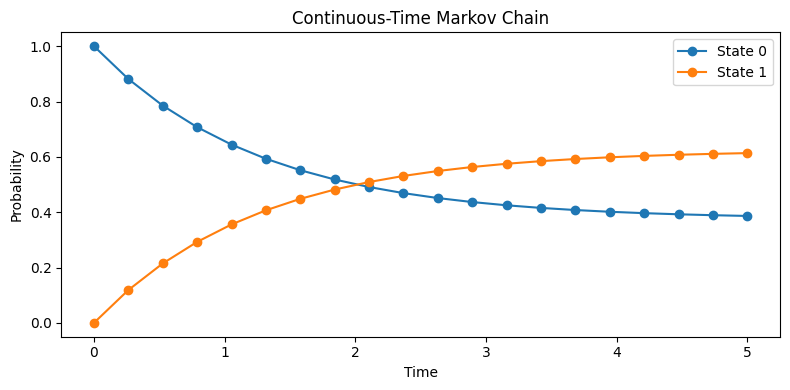

In [8]:
# Generator: rate 0.5 from state 0→1, rate 0.3 from state 1→0
L = np.array([[-0.5,  0.3],
              [ 0.5, -0.3]])

print("Column sums of L (must be 0):", L.sum(axis=0))

times = np.linspace(0, 5, 20).tolist()
markov = make_markov_chain(n_states=2, generator=L, times=times)

p0 = np.array([1.0, 0.0])
fig = plot_probability_evolution(markov, p0, title="Continuous-Time Markov Chain")
plt.tight_layout()
plt.show()


<!-- expansion:01:howto-ctmc-plot -->
### 🧭 How to use this cell / what to look at

- **What it computes:** a CTMC with the generator $L$ above, sampled at 20 evenly spaced times from 0 to 5 (spacing $5/19 \approx 0.263$). `make_markov_chain` turns each gap into an increment `expm(L * dt)`, so internally this is a `StochasticProcess` whose increments happen to all be equal.
- **What to look at:** the printed column sums `[0. 0.]`, then the figure. State 0 starts at 1 and decays smoothly toward 0.375; state 1 rises toward 0.625. These are the stationary values derived in the 🧮 cell above, not values printed by this cell. The worked formula predicts $p_0(5) = 0.375 + 0.625\,e^{-4} \approx 0.386$, so the curve is close to, but not yet at, its limit by the right edge of the plot.
- **What the shape tells you:** a single exponential approach with rate $a + b = 0.8$. No oscillation, no overshoot. A two-state Markov chain cannot oscillate, because its only non-zero eigenvalue is real and negative. Quantum two-state probabilities, by contrast, oscillate ($\cos^2$), which is the first visible hint that they cannot come from a generator like this.

**Try this.**
1. Make state 1 absorbing: `L = [[-0.5, 0.0], [0.5, 0.0]]`. Predict: state 0 decays as $e^{-0.5t}$ all the way to 0; this is the decay generator of WAY 3 with $\lambda = 0.5$.
2. Break the rule on purpose: `L = [[-0.5, -0.3], [0.5, 0.3]]` (a negative off-diagonal). The column sums still print 0, but state 0's probability heads toward $-1.5$ (it passes about $-0.58$ by $t = 5$), leaving $[0, 1]$ and the plot's fixed axis range. Column sums alone do not make a generator, just as they do not make a transition matrix.


In [9]:
# 📖 In depth: everything claimed about the generator, verified numerically.
from scipy.linalg import expm

np.set_printoptions(precision=4, suppress=True)
print("L =\n", L, "\n")

# --- 1. columns sum to 0, rows do NOT (the convention trap) ---------------
print(f"column sums : {L.sum(axis=0)}   <- zero, as required")
print(f"row sums    : {L.sum(axis=1)}   <- NOT zero (textbooks transpose this)\n")

# --- 2. L is the derivative of T at t=0:  T(dt) ~= I + L*dt ---------------
dt = 0.01
print(f"expm(L*{dt}) =\n{expm(L*dt)}")
print(f"I + L*{dt}   =\n{np.eye(2) + L*dt}")
print(f"max difference: {np.abs(expm(L*dt) - (np.eye(2)+L*dt)).max():.2e}  (O(dt^2))\n")

# --- 3. expm is NOT elementwise exp --------------------------------------
print(f"expm(L*1.0) col sums   : {expm(L*1.0).sum(axis=0)}   <- valid")
print(f"np.exp(L*1.0) col sums : {np.exp(L*1.0).sum(axis=0)}   <- garbage\n")

# --- 4. mean holding time = 1/|L_jj| -------------------------------------
for j in range(2):
    print(f"state {j}: outflow rate {abs(L[j,j]):.1f}/unit time"
          f"  ->  mean holding time {1/abs(L[j,j]):.2f}")

# --- 5. stationary distribution: the null vector of L --------------------
w, v = np.linalg.eig(L)
p_star = v[:, np.argmin(np.abs(w))].real
p_star = p_star / p_star.sum()
print(f"\neigenvalues of L : {w.real}   <- one is exactly 0")
print(f"stationary p*    : {p_star}   (L @ p* = {L @ p_star})")
print(f"expm(L*100) col0 : {expm(L*100)[:,0]}   <- converges to p*, as it must\n")

# --- 6. semigroup property => divisibility is automatic ------------------
t, s = 0.7, 1.3
print(f"T({t+s}) == T({t}) @ T({s}) ?  {np.allclose(expm(L*(t+s)), expm(L*t) @ expm(L*s))}")
factored = expm(L*s)
print(f"  the factored-out piece expm(L*{s}):  min entry {factored.min():.4f} (>=0), "
      f"col sums {factored.sum(axis=0)}")
print("  -> a perfectly valid transition matrix. This is why CTMCs are always divisible.")

L =
 [[-0.5  0.3]
 [ 0.5 -0.3]] 

column sums : [0. 0.]   <- zero, as required
row sums    : [-0.2  0.2]   <- NOT zero (textbooks transpose this)

expm(L*0.01) =
[[0.995 0.003]
 [0.005 0.997]]
I + L*0.01   =
[[0.995 0.003]
 [0.005 0.997]]
max difference: 1.99e-05  (O(dt^2))

expm(L*1.0) col sums   : [1. 1.]   <- valid
np.exp(L*1.0) col sums : [2.2553 2.0907]   <- garbage

state 0: outflow rate 0.5/unit time  ->  mean holding time 2.00
state 1: outflow rate 0.3/unit time  ->  mean holding time 3.33

eigenvalues of L : [-0.8  0. ]   <- one is exactly 0
stationary p*    : [0.375 0.625]   (L @ p* = [-0.  0.])
expm(L*100) col0 : [0.375 0.625]   <- converges to p*, as it must

T(2.0) == T(0.7) @ T(1.3) ?  True
  the factored-out piece expm(L*1.3):  min entry 0.2425 (>=0), col sums [1. 1.]
  -> a perfectly valid transition matrix. This is why CTMCs are always divisible.


<!-- expansion:01:howto-generator-checks -->
### 🧭 How to use this cell / what to look at

Six numbered blocks, one per claim in the In-depth cells above.

1. **Convention.** Column sums `[0. 0.]`, row sums `[-0.2 0.2]`. If you ever see a generator whose rows sum to 0 and columns do not, it was written in the textbook convention and must be transposed before use here.
2. **$L$ is the derivative at 0.** At $dt = 0.01$ the two printed matrices agree to three decimals and the maximum difference is `1.99e-05`. The error is $O(dt^2)$: the next term of the series is $L^2 dt^2/2$, and with $dt^2 = 10^{-4}$ that is about $2 \times 10^{-5}$, matching the print.
3. **`expm` vs `np.exp`.** `expm` gives column sums `[1. 1.]`; elementwise `np.exp` gives `[2.2553 2.0907]`. Check one by hand: $e^{-0.5} + e^{0.5} \approx 0.6065 + 1.6487 = 2.2553$.
4. **Holding times.** `2.00` and `3.33`: state 1 leaks out more slowly, so it is where the chain spends more time.
5. **Stationary distribution.** Eigenvalues `[-0.8  0. ]` and $\mathbf{p}^* =$ `[0.375 0.625]`, both derived by hand in the 🧮 cell. Notice the stationary probabilities are in the *same ratio* as the holding times: $0.375 : 0.625 = 2.00 : 3.33$. For two states that is not a coincidence: $p_j^* \propto 1/|L_{jj}|$ follows from the flow-balance equation $a\,p_0^* = b\,p_1^*$.
6. **Divisibility of the CTMC.** `True` for $T(2.0) = T(0.7)\,T(1.3)$, and the factor $e^{1.3L}$ has minimum entry `0.2425` with column sums `[1. 1.]`.

**Try this.**
1. In block 6, try many splits at once: loop `s` over `np.linspace(0.01, 1.99, 50)` and record `expm(L*s).min()`. Predict: every value is positive, because the off-diagonal entries are $0.375(1 - e^{-0.8s})$ and $0.625(1 - e^{-0.8s})$, both positive for $s > 0$.


<!-- expansion:01:recap-s3 -->
### 📝 Recap: Section 3

- A **continuous-time Markov chain** is generated by a rate matrix $L$ (off-diagonals $\ge 0$, columns sum to 0), with $T(\Delta t) = e^{L\Delta t}$ computed by `expm`, not elementwise `exp`.
- The **Markov property** (memorylessness) plus time-homogeneity gives the **semigroup property** $T(t+s) = T(t)\,T(s)$, and the semigroup property (with continuity) forces the exponential form.
- By Norris Theorem 2.1.2 (transposed), $e^{tL}$ is stochastic for **every** $t \ge 0$ exactly when $L$ is a valid generator, so every sub-interval has a valid transition matrix: **CTMCs are always divisible**.
- For two states everything is solvable by hand: eigenvalues $0$ and $-(a+b)$, stationary $\big(b, a\big)/(a+b)$, exponential approach, no oscillation.


### 🔭 Looking ahead: the column-sum rule is *not* what quantum mechanics breaks

Worth carrying forward into notebooks 02–03, because the natural guess is wrong.

A **stochastic matrix** satisfies two independent conditions:

| | condition | meaning |
|---|---|---|
| **(a)** | every column sums to 1 | probability is conserved — *complete* |
| **(b)** | every entry $\geq 0$ | entries really are probabilities — *valid* |

It's tempting to assume quantum weirdness breaks **(a)** — that somehow probability stops adding up. **It does not.** Condition (a) is remarkably robust:

* it is preserved under matrix multiplication — if $A$ and $B$ are column-stochastic, so is $BA$;
* it survives even the *matrix inversion* that `check_divisibility()` performs when it solves for a required intermediate matrix.

What fails is **(b)**. The next cell takes the qubit from notebook 03, asks what matrix would have to carry the process from $t=1.5$ to $t=2.0$, and finds:

$$T(t{=}2.0 \leftarrow t{=}1.5) = \begin{pmatrix} -2.4415 & 3.4415 \\ 3.4415 & -2.4415 \end{pmatrix}$$

Columns sum to exactly 1. Probability is perfectly conserved. The matrix simply demands a **$-244\%$ probability** for one transition, offset by $+344\%$ for the other.

That is the crack quantum mechanics comes through — and `isp/divisibility.py` encodes exactly this priority: `check_divisibility` tests for `negative_entries` first and `normalization_violated` second, and `indivisibility_signature()` measures *only* the magnitude of the most negative entry. **Whenever the required intermediate matrix exists, indivisibility shows up as a failure of non-negativity, never of normalization.** (When $\Gamma(t_1,t_0)$ is singular there may be no intermediate matrix at all; the four-tools cell below covers that case.)

So the column-sum rule isn't bookkeeping to accept and move past. It's the constraint that *stays true on both sides of the classical/quantum boundary* — which is precisely what makes it the right coordinate system for comparing them.

In [10]:
# 🔭 Looking ahead: which of the two conditions actually breaks?
# (Peeking at notebook 03's qubit. Nothing here is needed for notebook 01.)

from isp.quantum import make_qubit_sigmax_process

np.set_printoptions(precision=4, suppress=True)

# --- (a) column sums survive matrix multiplication -------------------------
A = np.array([[0.8, 0.3], [0.2, 0.7]])
B = np.array([[0.9, 0.1], [0.1, 0.9]])
print("classical: col sums of A =", A.sum(axis=0),
      " B =", B.sum(axis=0), " B@A =", (B @ A).sum(axis=0))

# --- (b) ...and they survive even the INVERSE step used by the -------------
#         divisibility test, on a genuinely quantum process.
q_times = list(np.linspace(0, 2.0, 5))          # t = 0, 0.5, 1.0, 1.5, 2.0
qubit   = make_qubit_sigmax_process(1.0, q_times)

# "What matrix must carry the process from t=1.5 to t=2.0, given where it
#  started?"  Solve T(t4<-t0) = X @ T(t3<-t0)  for X.
T_04 = qubit.transition_from_to(0, 4)
T_03 = qubit.transition_from_to(0, 3)
candidate = T_04 @ np.linalg.inv(T_03)

print("\nquantum: required intermediate matrix T(t=2.0 <- t=1.5):")
print(candidate)
print(f"\n  column sums : {candidate.sum(axis=0)}   <- STILL exactly 1. Normalization is fine.")
print(f"  min entry   : {candidate.min():.4f}        <- NEGATIVE. This is the violation.")
print("\n  Probability is perfectly conserved. The matrix simply demands a")
print(f"  {candidate.min()*100:.0f}% probability for one transition, offset by "
      f"+{candidate.max()*100:.0f}% for the other.")

classical: col sums of A = [1. 1.]  B = [1. 1.]  B@A = [1. 1.]

quantum: required intermediate matrix T(t=2.0 <- t=1.5):
[[-2.4415  3.4415]
 [ 3.4415 -2.4415]]

  column sums : [1. 1.]   <- STILL exactly 1. Normalization is fine.
  min entry   : -2.4415        <- NEGATIVE. This is the violation.

  Probability is perfectly conserved. The matrix simply demands a
  -244% probability for one transition, offset by +344% for the other.


<!-- expansion:01:derivation-qubit-negative -->
### 🧭 How to use this cell / what to look at

- **Block (a):** `A`, `B` and `B@A` all print column sums `[1. 1.]`. The product of column-stochastic matrices is column-stochastic.
- **Block (b):** the qubit process from `isp/quantum.py`, sampled at $t = 0, 0.5, 1.0, 1.5, 2.0$. The cell solves for the one matrix $X$ that would carry $t = 1.5$ to $t = 2.0$, and prints it: diagonal `-2.4415`, off-diagonal `3.4415`. Columns sum to 1; entries are not probabilities.
- **The two numbers that matter:** the column sums (fine) and the minimum entry (negative). That pair is the whole message of the cell.

### 🧮 Worked derivation: where $-2.4415$ comes from

This can be done with pencil and paper, and it shows *why* the failure happens, not just that it does.

**Step 1 — the qubit's matrices.** For $H = \frac{\omega}{2}\sigma_x$ with $\omega = 1$, `isp/quantum.py` gives the transition matrix from $t_0 = 0$ as

$$\Gamma(t \leftarrow 0) = \begin{pmatrix} f & 1-f \\ 1-f & f \end{pmatrix}, \qquad f(t) = \cos^2(t/2).$$

This is the shape of 2302.10778 eq. 7, quoted earlier.

**Step 2 — diagonalize the whole family at once.** Every matrix of this symmetric form has eigenvectors $(1,1)^{\mathsf T}$ with eigenvalue 1, and $(1,-1)^{\mathsf T}$ with eigenvalue $2f - 1$. Using $2\cos^2\theta - 1 = \cos 2\theta$,

$$2f(t) - 1 = \cos t.$$

Because all members share eigenvectors, they commute, and composing them just multiplies the second eigenvalues.

**Step 3 — solve for the bridge.** We need $X$ with $\Gamma(2.0 \leftarrow 0) = X\,\Gamma(1.5 \leftarrow 0)$. Since $\cos 1.5 \ne 0$ the inverse exists, $X$ is unique, and it has the same symmetric form with second eigenvalue

$$\lambda_X = \frac{\cos 2.0}{\cos 1.5} = \frac{-0.41615}{0.07074} \approx -5.883.$$

**Step 4 — convert back to entries.** For the form $\begin{pmatrix} g & 1-g \\ 1-g & g \end{pmatrix}$, the eigenvalue is $2g - 1$, so

$$g = \frac{1 + \lambda_X}{2} \approx \frac{1 - 5.883}{2} \approx -2.4415, \qquad 1 - g \approx 3.4415.$$

These are the printed entries.

**Step 5 — the general rule for this family.** $X$ is a genuine stochastic matrix exactly when $0 \le g \le 1$, i.e. $|\lambda_X| \le 1$, i.e.

$$|\cos t_2| \le |\cos t_1|.$$

For the two-state Markov chains of this notebook, the second eigenvalue can only shrink in magnitude over time (Section 3: $e^{-(a+b)t}$). The qubit's $|\cos t|$ shrinks until $t = \pi/2 \approx 1.571$ and then **grows again**: the probabilities "re-cohere." Any bridge from a time $t_1$ to a later time $t_2$ with $|\cos t_2| > |\cos t_1|$ (possible only once the window passes $\pi/2$) would have to amplify a contrast that a stochastic matrix can only shrink, so it needs negative entries. Here $t_1 = 1.5$ sits just before $\pi/2$, where $|\cos t_1| = 0.071$ is tiny, which is why the required amplification (5.9×) and the negative entry are so large.

**Try this.**
1. Change `q_times` to `np.linspace(0, 1.4, 5)` (all before $\pi/2$). Predict: the bridge from $t_3$ to $t_4$ now has $|\cos t_4| < |\cos t_3|$, so its entries are all non-negative (diagonal about $0.67$). On a window that ends before $\pi/2$, $|\cos t|$ only shrinks, so the bridge between any two sampled times is a valid stochastic matrix and the sampled qubit looks divisible.
2. Pick times straddling $\pi/2$ more closely, e.g. $t_3 = 1.56$, $t_4 = 1.6$: $\cos 1.56 \approx 0.0108$ and $\cos 1.6 \approx -0.0292$, so $\lambda_X \approx -2.7$ and $g \approx -0.85$. Different numbers, same sign of failure.


### 🔭 Looking ahead: four tools for one condition, and why the lab needed all four

`isp/divisibility.py` grew over time, and the order it grew in is instructive — each function fixes a failure of the one before. Worth meeting them here, because notebooks 02 and 03 use the early ones and notebook 05 needs the late ones.

| function | question it answers | returns | needs an inverse? |
|---|---|---|---|
| `check_divisibility` | is this process divisible? | verdict + `failure_mode` | **yes** |
| `indivisibility_signature` | *how* indivisible? | most negative entry found | **yes** |
| `check_divisibility_lp` | does *any* valid intermediate exist? | verdict + `defect` + a witness | no |
| `divisibility_defect` | how far from divisible? | smallest achievable $L_1$ residual | no |

#### The first two solve for the intermediate matrix

Both rearrange $\Gamma(t_2,t_0) = \Gamma(t_2,t_1)\Gamma(t_1,t_0)$ into

$$\Gamma(t_2,t_1) \;=\; \Gamma(t_2,t_0)\,\Gamma(t_1,t_0)^{-1}$$

then inspect the answer. That is a fine move when $\Gamma(t_1,t_0)$ is invertible: there is exactly one candidate, and you check whether it is a legal transition matrix. `check_divisibility` tests the two conditions in the order they matter — negative entries first (`divisibility.py:50`), normalization second (`divisibility.py:62`) — which encodes the point made just above: when the intermediate matrix exists, indivisibility is a failure of non-negativity, never of normalization.

#### Why that is not enough

The inverse only exists sometimes. When it does not, `check_divisibility` returns `divisible: None` with `failure_mode="singular_matrix"`: **undecided**, not a verdict. It says the method failed, not that the process did, and its message points to `check_divisibility_lp`. And `indivisibility_signature` handles the same case worse:

```python
if abs(np.linalg.det(T_ij)) < tol:
    continue                      # divisibility.py:93-94 — skip this triple
```

It skips silently and keeps going.

> ⚠️ **The consequence is not hypothetical, and it is bad.** Run `indivisibility_signature()` on the fully coherent double slit of notebook 05 — the most indivisible process in this repo — and it returns **`0.0`**. That process has three times, so a single triple, and its $\Gamma(t_1,t_0)$ is singular; the triple is skipped, and the function reports the value it also reports for a classical Markov chain. A measure of indivisibility that returns zero for the flagship indivisible case is worse than no measure, because it looks like an answer.

This is not a coding slip that a `try/except` would fix. The balanced double slit makes $\Gamma(t_1,t_0)$ singular *structurally* — unitarity forces the two slit rows of $|U_1|^2$ to be identical, so the matrix is rank-deficient for every model of that shape, at every size. Notebook 05 proves it. The inverse-based test is not merely inconclusive there; it is unavailable in principle.

#### What replaces it

The last two functions go back to the condition as Barandes states it — *does there exist any valid stochastic $\Gamma(t_2,t_1)$?* — and answer it as a **linear program** over the entries of the unknown matrix, with $M \ge 0$ and unit column sums as the constraints. No inverse appears, so singularity is simply irrelevant, and "no such matrix exists" becomes a proved result rather than a failed method.

On the coherent double slit, where the inverse-based pair reports `singular_matrix` and `0.0`:

$$\texttt{check\_divisibility\_lp} \;\to\; \texttt{divisible=False},\quad \texttt{defect} = 11.998165$$

Notebook 02 develops why this is the natural formulation, and notebook 05 runs it on the model that forced the rewrite.

<!-- expansion:01:papers-divisibility-origin -->
### 📚 From the papers: where "divisible" comes from, and what it is not

A few source facts that frame the four tools above.

- **The term.** 2302.10778 §2.1 says the word "divisible" "seems to have originated in the research literature in a 2008 paper by Wolf and Cirac (2008) in the context of quantum channels," and that $\Gamma(t \leftarrow t_0)$ "will generically be indivisible ... meaning that for intermediate times $t'$ ... there will not generally exist a genuinely stochastic matrix $\tilde\Gamma(t \leftarrow t')$" satisfying the composition law (eq. 6); for "generically" he cites Milz and Modi (2021). The phrase *genuinely stochastic* is the condition the LP tools test directly.
- **Not infinite divisibility.** Both papers warn (2302.10778 footnote 4; 2507.21192 footnote 1) that this is unrelated to the older notion of an *infinitely divisible* probability distribution. If you search for "divisible distribution" you will find the wrong concept.
- **The nLab summary** ("indivisible stochastic process interpretation of quantum mechanics") states divisibility as $P(t_1, t_0) = P(t_1, t)\cdot P(t, t_0)$ for all intermediate $t$, and gives the short reason quantum processes fail it: the Born rule makes $P_{ij} = |\Theta_{ij}|^2$, and it is the amplitudes $\Theta$ that compose by matrix multiplication, so "the corresponding (doubly) stochastic matrices $P$ of transition probabilities will clearly not compose by the rules of matrix multiplication." The 🧮 derivation above is one explicit instance.

**General knowledge, not from the sources above:** the LP formulation used by `check_divisibility_lp` is a standard feasibility problem (find $M \ge 0$ with unit column sums and $M\,\Gamma(t_1 \leftarrow t_0) = \Gamma(t_2 \leftarrow t_0)$); the specific `defect = 11.998165` figure quoted in the cell above is the lab's own result for notebook 05's model, not a number from the papers.


## Summary

- Stochastic states are column vectors; transition matrices left-multiply
- Every column of $T$ sums to 1 and has non-negative entries
- Time-homogeneous continuous-time Markov chains are generated by a fixed rate matrix $L$:
  $T(\Delta t) = e^{L \cdot \Delta t}$ for any elapsed time $\Delta t \ge 0$

**Next:** Notebook 02 examines the *divisibility* of these processes: whether the transition
matrix from the start can be factored through an intermediate time using a valid stochastic
matrix. Every Markov chain passes. The condition constrains first-order transition matrices
only (Paper 1, §2.2), so a divisible process can still have memory in its higher-order
statistics, and an indivisible one is not simply a process "with memory" in the usual sense.
Barandes's stochastic-quantum correspondence covers a "highly general class" of processes,
divisible or not (Paper 1, §1; Paper 2, abstract). Indivisible is the generic case (Paper 1, §2.1,
in the sentence introducing eq. 6, citing Milz & Modi (2021)), and it is the case unitary quantum
evolution typically produces (Paper 1, §3.5).


<!-- expansion:01:final-recap -->
### 📝 Notebook recap and where to go next

**What you should now be able to do.**
- Write a probability vector and a column-stochastic transition matrix for a small system, and check both conditions (non-negativity, normalization) separately.
- Evolve a distribution through one or several matrices by hand, and say why the latest matrix goes on the left.
- Find the stationary distribution and the relaxation rate of any two-state chain, discrete ($1 - a - b$ per step) or continuous ($e^{-(a+b)t}$).
- Build a CTMC from a generator, explain why it needs `expm`, and explain why it is automatically divisible (semigroup property plus Norris Theorem 2.1.2).
- Explain, with the qubit example, that quantum processes keep the column-sum rule and break non-negativity of the *intermediate* matrix.

**The key distinction to carry forward.** In the papers' terms, a textbook Markov process has transition matrices for *every* pair of times, and they compose. An indivisible stochastic process is specified only by $\Gamma(t \leftarrow t_0)$ from its division events (2507.21192 §2.2), and the matrices that would bridge intermediate times need not exist as stochastic matrices.

**Open questions worth holding onto.**
- If a process is divisible, must it be Markov? (No in general; notebook 08 examines the gap.)
- What should "how indivisible" mean when the inverse does not exist? (Notebooks 02 and 05.)
- Where does the $|U_{ij}|^2$ form of the qubit's matrices come from? (Notebook 04, unistochastic matrices.)

**Next:** [Notebook 02: Divisibility](02_divisibility_annotated.ipynb) turns the composition condition into a test, `check_divisibility`, and runs it on the processes built here. Then [Notebook 03: Indivisibility](03_indivisibility_annotated.ipynb) applies it to the qubit and finds the negative entry derived above.
